# PRN waveform for the RFSoC 4x2 (runs on the board)

Generates the transmit waveform on the board's ARM processor and packs it in the format the DAC stream expects, ready to be written into the waveform memory of the custom overlay (`fpga/prn_player.v`).

Same chain as the simulation notebook (`simulation/tx_spectrum_sim.ipynb`, sections 1–2): LFSR → BPSK → upsample → RRC. Only NumPy and Matplotlib are needed, so the two functions used from `tx_model.py` are copied in here.

**Rates in the base overlay** (read back on the board, 2026-10-09):

| Stage | Rate | Samples per chip |
|---|---|---|
| DAC sample rate | 4.9152 GS/s | 96 |
| RF Data Converter interpolation | ×2 | |
| **FPGA stream into the DAC (generated here)** | **2.4576 GS/s complex** | **48** |
| FPGA fabric clock | 307.2 MHz, 8 complex samples per clock = one 256-bit word | |

The simulation's `SPS_FPGA = 8` becomes **48** here, because the base overlay interpolates only ×2 in hardware instead of ×12. Chip rate, β and span are unchanged.

### 1. Parameters

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

FS_DAC    = 4.9152e9              # DAC sample rate [Hz]
INTERP_HW = 2                     # interpolation inside the RF Data Converter (base overlay)
FS_PLAY   = FS_DAC / INTERP_HW    # 2.4576 GS/s complex: rate of the samples generated here
SPS_DAC   = 96                    # DAC samples per chip -> CHIP_RATE = FS_DAC / 96 = 51.2 Mcps
CHIP_RATE = FS_DAC / SPS_DAC
SPS_PLAY  = SPS_DAC // INTERP_HW  # 48 samples per chip in the FPGA stream

NBITS     = 9                     # 511 chips = 10.0 us: one period fits in one 32768-sample ADC capture
BETA      = 0.35                  # RRC roll-off
SPAN      = 16                    # RRC length in chips
PEAK_AMP  = 0.5                   # waveform peak as a fraction of DAC full scale

SAMPLES_PER_WORD = 8              # complex samples per 256-bit stream word
PACKING   = "interleaved"         # layout of I/Q inside a 256-bit word (section 4): "interleaved" or "split"

print(f"chip rate     : {CHIP_RATE / 1e6:.1f} Mcps")
print(f"playback rate : {FS_PLAY / 1e9:.4f} GS/s complex, {SPS_PLAY} samples per chip")

chip rate     : 51.2 Mcps
playback rate : 2.4576 GS/s complex, 48 samples per chip


### 2. LFSR and RRC (copied from `tx_model.py`)

In [2]:
# Feedback taps of maximal-length LFSRs (Xilinx XAPP052), key = register length n
LFSR_TAPS = {7: (7, 6), 9: (9, 5), 10: (10, 7), 11: (11, 9)}

def mseq(nbits=10):
    # one period (2^n - 1 chips) of an m-sequence of 0/1 bits from a Fibonacci LFSR
    taps  = LFSR_TAPS[nbits]
    state = np.ones(nbits, dtype=np.int8)          # any non-zero start state
    n     = 2 ** nbits - 1
    out   = np.empty(n, dtype=np.int8)
    for i in range(n):
        out[i] = state[-1]                          # output = last stage
        fb = np.bitwise_xor.reduce(state[[t - 1 for t in taps]])   # XOR of the tap stages
        state = np.roll(state, 1)                   # shift
        state[0] = fb                               # feedback into the first stage
    assert out.sum() == 2 ** (nbits - 1), "not maximal length: check taps"
    return out

def rrc_taps(beta, sps, span):
    # root-raised-cosine impulse response, span chips long, sps samples per chip, unit energy
    t = np.arange(-(span * sps) // 2, (span * sps) // 2 + 1) / sps    # time in chips
    h = np.empty(t.size)
    for i, ti in enumerate(t):
        if np.isclose(ti, 0.0):
            h[i] = 1 - beta + 4 * beta / np.pi                        # limit at t = 0
        elif beta > 0 and np.isclose(abs(ti), 1 / (4 * beta)):
            h[i] = (beta / np.sqrt(2)) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta))
                                          + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))   # limit at t = +/- 1/(4 beta)
        else:
            h[i] = ((np.sin(np.pi * ti * (1 - beta)) + 4 * beta * ti * np.cos(np.pi * ti * (1 + beta)))
                    / (np.pi * ti * (1 - (4 * beta * ti) ** 2)))
    return h / np.sqrt(np.sum(h ** 2))

### 3. The PRN waveform at 48 samples per chip

Exactly sections 2a and 2c of the simulation, at the playback rate: BPSK chips, zero-stuffed to 48 samples per chip, then filtered with the RRC by circular convolution (the waveform is played in a loop, so one period filtered circularly is exactly the continuous signal). The filter delay is removed so that chip $k$ peaks at sample $48k$.

The result is real (BPSK): it goes on **I**, and **Q = 0**. The RF Data Converter's complex-to-real mixer then outputs $I\cos(\omega_{NCO} t)$.

Length check: one period is $511 \times 48 = 24528$ samples $= 3066$ words of 8 samples. It has to be a whole number of words so that the loop has no gap.

In [3]:
chips = 1.0 - 2.0 * mseq(NBITS)                   # 0 -> +1, 1 -> -1
up    = np.zeros(chips.size * SPS_PLAY)
up[::SPS_PLAY] = chips                            # one chip every 48 samples

h     = rrc_taps(BETA, SPS_PLAY, SPAN)            # 16 x 48 + 1 = 769 taps
wave  = np.real(np.fft.ifft(np.fft.fft(up) * np.fft.fft(h, up.size)))
wave  = np.roll(wave, -(h.size // 2))             # remove the filter delay
wave *= PEAK_AMP / np.max(np.abs(wave))           # peak = PEAK_AMP of full scale

N_SAMPLES = wave.size
N_WORDS   = N_SAMPLES // SAMPLES_PER_WORD
assert N_SAMPLES % SAMPLES_PER_WORD == 0, "period is not a whole number of 256-bit words"

papr_db = 10 * np.log10(np.max(wave ** 2) / np.mean(wave ** 2))
print(f"{chips.size} chips, {N_SAMPLES} samples, {N_WORDS} words of 256 bits ({N_WORDS * 32 / 1024:.1f} KiB)")
print(f"period {N_SAMPLES / FS_PLAY * 1e6:.3f} us, line spacing {CHIP_RATE / chips.size / 1e3:.1f} kHz, PAPR {papr_db:.2f} dB")
print(f"RMS level {20 * np.log10(np.sqrt(np.mean(wave ** 2))):.1f} dBFS (peak {20 * np.log10(PEAK_AMP):.1f} dBFS)")

511 chips, 24528 samples, 3066 words of 256 bits (95.8 KiB)
period 9.980 us, line spacing 100.2 kHz, PAPR 4.02 dB
RMS level -10.0 dBFS (peak -6.0 dBFS)


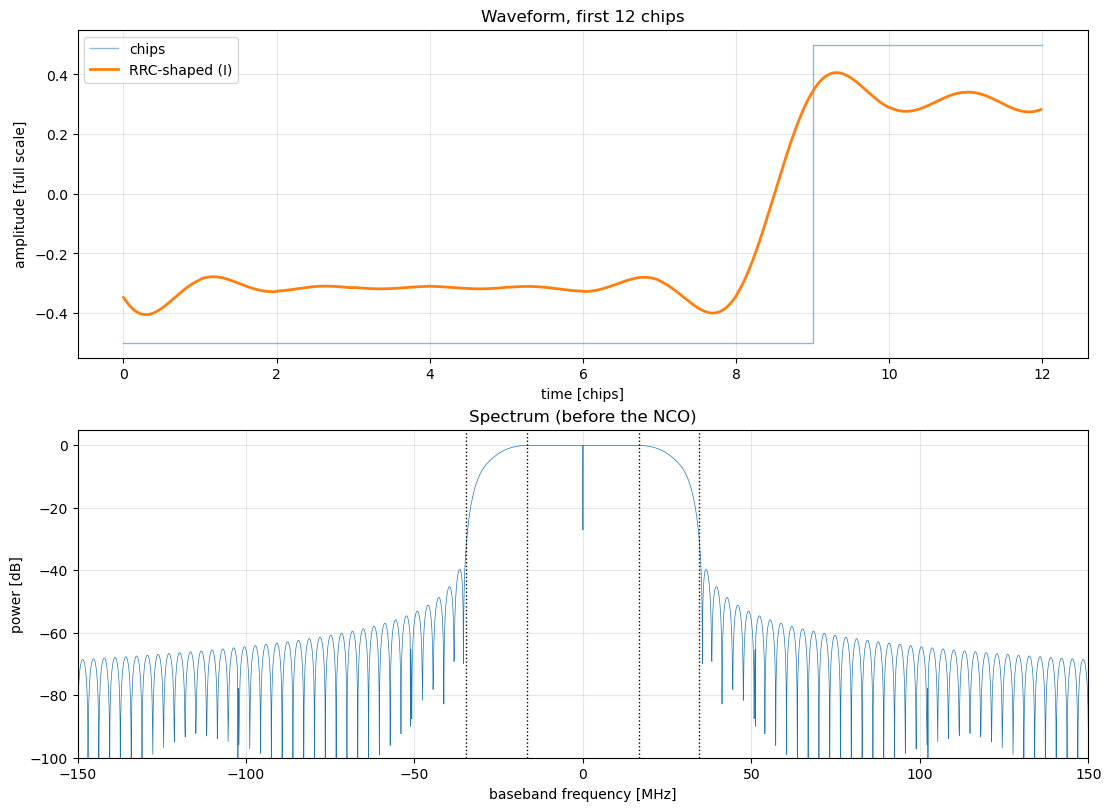

In [4]:
# time domain: first chips, with the chip values for reference
N_SHOW = 12
t_chip = np.arange(N_SHOW * SPS_PLAY) / SPS_PLAY
fig, ax = plt.subplots(2, 1, figsize=(11, 8), layout='constrained')
ax[0].step(np.arange(N_SHOW + 1), PEAK_AMP * np.append(chips[:N_SHOW], chips[N_SHOW - 1]),
           where="post", lw=1, alpha=0.5, label="chips")
ax[0].plot(t_chip, wave[:N_SHOW * SPS_PLAY], lw=2, label="RRC-shaped (I)")
ax[0].set(xlabel="time [chips]", ylabel="amplitude [full scale]", title=f"Waveform, first {N_SHOW} chips")
ax[0].legend(); ax[0].grid(alpha=0.3)

# spectrum of one period (lines every CHIP_RATE / 511 = 100 kHz)
f = np.fft.fftshift(np.fft.fftfreq(N_SAMPLES, 1 / FS_PLAY))
P = np.fft.fftshift(np.abs(np.fft.fft(wave)) ** 2)
ax[1].plot(f / 1e6, 10 * np.log10(P / P.max() + 1e-15), lw=0.5)
for e in ((1 - BETA) * CHIP_RATE / 2, (1 + BETA) * CHIP_RATE / 2):
    for s in (-1, 1):
        ax[1].axvline(s * e / 1e6, color="k", ls=":", lw=1)
ax[1].set(xlabel="baseband frequency [MHz]", ylabel="power [dB]", title="Spectrum (before the NCO)",
          xlim=(-150, 150), ylim=(-100, 5))
ax[1].grid(alpha=0.3)

### 4. Packing into 256-bit words

The DAC stream carries 8 complex samples per 307.2 MHz clock, each as signed 16-bit I and Q. How they are arranged inside the 256-bit word is **not yet verified on this board** (the base overlay's amplitude controller always sends I = Q, so it does not reveal the order). The two likely layouts:

* `"interleaved"`: each 32-bit slot is one complex sample, I in the low 16 bits and Q in the high 16 bits: `I0 Q0 I1 Q1 ... I7 Q7` (from bit 0 upwards).
* `"split"`: the low 128 bits hold the 8 I samples, the high 128 bits the 8 Q samples: `I0 ... I7 Q0 ... Q7`.

The tone test in section 5 decides which one is right: with the wrong layout the tone comes out at the wrong frequency or as a mess.

In memory, word $k$ occupies bytes $32k \ldots 32k+31$, little-endian. So a flat `int16` array in the order above, written byte for byte into the waveform memory, puts every 16-bit value in the right place.

In [5]:
FULL_SCALE = 32767

def to_int16(x):
    # float in [-1, 1] full scale -> signed 16-bit, rounded and clipped
    return np.clip(np.round(np.asarray(x) * FULL_SCALE), -32768, 32767).astype(np.int16)

def pack_iq(i_samples, q_samples, packing=PACKING):
    # complex samples -> flat int16 array in memory order (16 values = one 256-bit word)
    i16, q16 = to_int16(i_samples), to_int16(q_samples)
    n = i16.size
    assert n % SAMPLES_PER_WORD == 0
    if packing == "interleaved":
        out = np.empty(2 * n, dtype=np.int16)
        out[0::2], out[1::2] = i16, q16                       # I0 Q0 I1 Q1 ...
    elif packing == "split":
        w = n // SAMPLES_PER_WORD
        out = np.concatenate([i16.reshape(w, SAMPLES_PER_WORD),
                              q16.reshape(w, SAMPLES_PER_WORD)], axis=1).ravel()   # I0..I7 Q0..Q7 per word
    else:
        raise ValueError(packing)
    return out

def unpack_iq(packed, packing=PACKING):
    # inverse of pack_iq (used to check the packing)
    p = np.asarray(packed, dtype=np.int16)
    if packing == "interleaved":
        i16, q16 = p[0::2], p[1::2]
    else:
        w = p.reshape(-1, 2 * SAMPLES_PER_WORD)
        i16, q16 = w[:, :SAMPLES_PER_WORD].ravel(), w[:, SAMPLES_PER_WORD:].ravel()
    return i16.astype(float) / FULL_SCALE, q16.astype(float) / FULL_SCALE

prn_packed = pack_iq(wave, np.zeros_like(wave))
i_back, q_back = unpack_iq(prn_packed)
print(f"packed PRN: {prn_packed.size} int16 values = {prn_packed.nbytes} bytes = {prn_packed.nbytes // 32} words")
print(f"round trip error: {np.max(np.abs(i_back - wave)) * FULL_SCALE:.2f} LSB (rounding only), Q all zero: {not q_back.any()}")

packed PRN: 49056 int16 values = 98112 bytes = 3066 words
round trip error: 0.50 LSB (rounding only), Q all zero: True


### 5. Tone test waveform (to check the packing)

A complex exponential $I + jQ = A\,e^{j 2\pi f_t n / f_s}$ at a known baseband frequency $f_t$. After the DAC's NCO (784.8 MHz) and the receiver's NCO (−784.8 MHz), it must appear at **exactly $+f_t$** in the ADC_C capture.

* $+f_t$: packing and I/Q order correct.
* $-f_t$: I and Q swapped (or the sign convention is flipped).
* At $\pm f_t$ both, or spread out: the layout is wrong; switch `PACKING` and repeat.

$f_t$ is chosen as a whole number of cycles per buffer, so the loop is seamless: the buffer is 24528 samples long, i.e. one cycle per buffer is $f_s / 24528 = 100.2$ kHz, and 100 cycles give $f_t = 10.02$ MHz.

In [6]:
N_CYCLES = 100                                     # whole number of cycles per buffer -> seamless loop
f_tone   = N_CYCLES * FS_PLAY / N_SAMPLES          # 10.02 MHz
n        = np.arange(N_SAMPLES)
tone     = PEAK_AMP * np.exp(2j * np.pi * N_CYCLES * n / N_SAMPLES)
tone_packed = pack_iq(tone.real, tone.imag)
print(f"test tone at {f_tone / 1e6:.4f} MHz baseband -> expect +{f_tone / 1e6:.4f} MHz in the ADC_C capture")

test tone at 10.0196 MHz baseband -> expect +10.0196 MHz in the ADC_C capture


### 6. Save

The packed arrays are saved as `.npy`, so they can be loaded directly in the overlay notebook (or copied between the board and the PC).

In [7]:
np.save("prn_nbits9_48sps_packed.npy", prn_packed)
np.save("tone_10p02MHz_packed.npy", tone_packed)
np.save("prn_nbits9_48sps_float.npy", wave)          # unpacked I samples, for the analysis on the RX side
print("saved:", "prn_nbits9_48sps_packed.npy, tone_10p02MHz_packed.npy, prn_nbits9_48sps_float.npy")

saved: prn_nbits9_48sps_packed.npy, tone_10p02MHz_packed.npy, prn_nbits9_48sps_float.npy


### 7. Load into the custom overlay (template)

Only once the custom overlay with `prn_player` exists (see `fpga/README.md`). The names below (`waveform_bram_ctrl`, `player_gpio`) are the ones suggested there; **use the names from your block design** (the cell prints the candidates from `ol.ip_dict`).

Register map of the AXI GPIO in the sample design:
* channel 1 (output, offset 0x0): bit 0 = `arm` (1 = play, 0 = stop), bit 1 = `free_run` (1 = start immediately, 0 = wait for the next PPS edge).
* channel 2 (output, offset 0x8): waveform length in 256-bit words (3066 here).

Use `FREE_RUN = True` for bench tests without a PPS source connected.

In [8]:
LOAD_TO_FPGA = False             # set True once the custom overlay is built and copied to the board
FREE_RUN     = True              # True: start immediately; False: start on the next PPS edge

if LOAD_TO_FPGA:
    from pynq import Overlay, MMIO
    ol = Overlay("prn_player.bit")                          # your custom overlay (.bit + .hwh with the same name)
    print([k for k in ol.ip_dict if "bram" in k or "gpio" in k])

    bram_info = ol.ip_dict["radio/transmitter/channel_00/waveform_bram_ctrl"]   # adjust to your design
    gpio_info = ol.ip_dict["radio/transmitter/channel_00/player_gpio"]          # adjust to your design
    bram = MMIO(bram_info["phys_addr"], bram_info["addr_range"])
    gpio = MMIO(gpio_info["phys_addr"], gpio_info["addr_range"])

    data = tone_packed                                       # first the tone test, then prn_packed
    gpio.write(0x0, 0)                                       # disarm (stop playback) while writing
    words32 = data.view(np.uint32)                           # same bytes, as 32-bit words for the AXI writes
    for k, v in enumerate(words32):                          # simple and safe; ~12k writes take well under a second
        bram.write(4 * k, int(v))
    gpio.write(0x8, data.nbytes // 32)                       # length in 256-bit words
    gpio.write(0x0, 0b11 if FREE_RUN else 0b01)              # bit 0 = arm, bit 1 = free run
    print("playing" if FREE_RUN else "armed: playback starts on the next PPS edge")